# Soil inputs for the EU production run — methods figures

This notebook documents every step of the soil stage that produced the soil
files of the **EU_val** export (`/data01/FDS/muduchuru/Data/SIMPLACE/EU_val`),
which drives the `winter_wheat_2000_2024_euval` production run. It reads the
run's **own** configuration (`_work/config_run.yaml`) and inputs, so every
figure describes the run as it was made, not a re-parameterised copy.

Two scales are used:

* **One 5° processing tile at native 250 m** (§2–§8). The run cached every
  SoilGrids coverage it downloaded per tile; the 250 m state is rebuilt from
  that cache with the package's own functions, and §1 checks it reproduces
  the run's intermediate NetCDF exactly.
* **The whole domain at 10 km** (§1, §9–§10), from the per-tile intermediate
  NetCDFs and the exported CSVs.

| § | Step | Scale |
| --- | --- | --- |
| 1 | Domain, tiling, exported cell set | Europe |
| 2 | SoilGrids 250 m inputs: un-scaling, no-data masking | Tile |
| 3 | Cropland filter (PROBA-V ≥ 80 %) | Tile |
| 4 | Composite texture classification (topsoil × rooting zone) | Tile |
| 5 | Dominant class per 10 km cell and pixel mask | Tile |
| 6 | Variable-specific aggregation rules | Tile |
| 7 | Post-processing: texture closure, water-retention ordering | Tile |
| 8 | Depth remapping onto the SIMPLACE layering, initial mineral N | Tile |
| 9 | Exported soil properties | Europe |
| 10 | Within-cell heterogeneity (top-3 classes) | Europe |
| 11 | Numbers for the methods text | Both |

Figures are written to `notebooks/outputs/soil_inputs/` as PNG (300 dpi) and
PDF.

## 0. Setup

In [1]:
import json
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm
from matplotlib.patches import Patch, Rectangle

import data4simplace
from data4simplace.config import load_config
from data4simplace.exporters.soil_export import remap_depth_weighted
from data4simplace.grid import TargetGrid, _standardise_lonlat_names
from data4simplace.soil.classify import (
    USDA_CLASSES,
    bin_reduce,
    cell_assignment,
    cell_mean,
    class_composition,
    depth_bounds_cm,
    dominant_pixel_mask,
    reducer_for,
    rootzone_mean,
    split_profile_class,
    usda_profile_class,
    usda_texture_class,
)
from data4simplace.soil.soilgrids import SCALE_FACTORS, SoilGridsHandler
from data4simplace.spatial.area import pixel_area_km2
from data4simplace.spatial.cropland_weights import CroplandWeights
from data4simplace.tiling import _tile_config, list_windows

warnings.filterwarnings("ignore", category=RuntimeWarning)

RUN = Path("/data01/FDS/muduchuru/Data/SIMPLACE/EU_val")
NC_DIR = RUN / "soil" / "netcdf_tiles"
TILE_DEG = 5.0  # D4S_TILE_DEG of the run (submit/env.sh)
TILE = 61       # index into list_windows: 8–13 °E, 47–52 °N (central and southern Germany)

REPO = Path(data4simplace.__file__).resolve().parents[2]
FIG_DIR = REPO / "notebooks" / "outputs" / "soil_inputs"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8,
    "axes.titlesize": 9, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlelocation": "left",
})


def save(fig: plt.Figure, name: str) -> None:
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")

Run configuration, the global target grid, and the tile window. The tile
config is derived exactly as `tiling._run_tile` derives it: the run config
with the grid bounds replaced by the tile's, and the tile's own WCS cache.

In [2]:
run_cfg = load_config(RUN / "_work" / "config_run.yaml")
grid_eu = TargetGrid.from_config(run_cfg.grid)
windows = list_windows(run_cfg, TILE_DEG)
window = windows[TILE]
tile_base = load_config(RUN / "_work" / "configs" / f"config_tile_{TILE}.yaml")
cfg = _tile_config(tile_base, grid_eu, window)
grid = TargetGrid.from_config(cfg.grid)
soil_cfg = cfg.soil

pd.Series({
    "dominant_mode": soil_cfg.dominant_mode,
    "aggregation_method": soil_cfg.aggregation_method,
    "n_primary_classes": soil_cfg.n_primary_classes,
    "cropland_min_fraction": soil_cfg.cropland_min_fraction,
    "min_cropland_pixels": soil_cfg.min_cropland_pixels,
    "rootzone_bottom_cm": soil_cfg.rootzone_bottom_cm,
    "export_statistic": soil_cfg.export_statistic,
    "fill_missing": soil_cfg.fill_missing,
    "long_depths": soil_cfg.long_depths,
    "mineral_n_fraction": soil_cfg.mineral_n_fraction,
    "ammonium_share": soil_cfg.ammonium_share,
    "layers": ", ".join(soil_cfg.layers),
    "depths": ", ".join(soil_cfg.depths),
    "target grid": f"{grid_eu.shape[0]} x {grid_eu.shape[1]} cells at {run_cfg.grid.resolution_deg} deg",
    "tiles": f"{len(windows)} x {TILE_DEG} deg",
    "example tile": f"{window.name}: {cfg.grid.min_lon:.0f}-{cfg.grid.max_lon:.0f} E, "
                    f"{cfg.grid.min_lat:.0f}-{cfg.grid.max_lat:.0f} N",
}, name="value").to_frame()

,value
dominant_mode,usda_profile
aggregation_method,top3
n_primary_classes,3
cropland_min_fraction,0.8
min_cropland_pixels,1
rootzone_bottom_cm,100.0
export_statistic,mean
fill_missing,False
long_depths,reference
mineral_n_fraction,0.01


### Shared plotting helpers

Texture classes are nominal, so they get one fixed colour each, keyed on the
class rather than its rank. The twelve-class map is the standard way texture
is shown; where composite codes would need more colours (§5) only the most
frequent seven are coloured and the rest fold into "other".

In [3]:
USDA_ABBR = {1: "C", 2: "SiC", 3: "SC", 4: "CL", 5: "SiCL", 6: "SCL",
             7: "L", 8: "SiL", 9: "Si", 10: "SL", 11: "LS", 12: "S"}
USDA_COLORS = {
    1: "#7b3294", 2: "#c2a5cf", 3: "#a6611a", 4: "#d6604d", 5: "#f4a582",
    6: "#dfc27d", 7: "#5aae61", 8: "#a6dba0", 9: "#1b7837", 10: "#fdd49e",
    11: "#fee391", 12: "#fff7bc",
}
USDA_CMAP = ListedColormap(["#ffffff"] + [USDA_COLORS[c] for c in USDA_CLASSES])
USDA_NORM = BoundaryNorm(np.arange(-0.5, 13.5), USDA_CMAP.N)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
OTHER, NONCROP = "#9e9e9e", "#f0f0f0"
EU_PROJ = ccrs.LambertAzimuthalEqualArea(central_longitude=10, central_latitude=52)
EU_EXTENT = [-11, 45, 34, 71]


def usda_legend(ax, codes=USDA_CLASSES, **kw):
    handles = [Patch(facecolor=USDA_COLORS[c], edgecolor="0.5", lw=0.3,
                     label=f"{USDA_ABBR[c]} {USDA_CLASSES[c].replace('_', ' ')}")
               for c in codes]
    return ax.legend(handles=handles, frameon=False, **kw)


def profile_abbr(code: int) -> str:
    top, root = split_profile_class(code)
    return f"{USDA_ABBR[top]}/{USDA_ABBR[root]}" if top else "–"


def show(ax, da: xr.DataArray, **kw):
    """Plate-carrée raster with the aspect of its mean latitude."""
    lat, lon = da["lat"].values, da["lon"].values
    im = ax.imshow(
        np.asarray(da.values), extent=[lon.min(), lon.max(), lat.min(), lat.max()],
        origin="upper" if lat[0] > lat[-1] else "lower", interpolation="nearest",
        aspect=1 / np.cos(np.deg2rad(lat.mean())), **kw,
    )
    ax.set_xlabel("Longitude [°E]")
    ax.set_ylabel("Latitude [°N]")
    return im


def cell_lines(ax, lon0, lon1, lat0, lat1, res=0.1, **kw):
    kw = {"color": "0.25", "lw": 0.4} | kw
    for x in np.arange(lon0, lon1 + 1e-9, res):
        ax.axvline(x, **kw)
    for y in np.arange(lat0, lat1 + 1e-9, res):
        ax.axhline(y, **kw)


def eu_axes(fig, spec, title=None):
    ax = fig.add_subplot(spec, projection=EU_PROJ)
    ax.set_extent(EU_EXTENT, ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#ebebeb", zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), lw=0.3, edgecolor="0.3")
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), lw=0.2, edgecolor="0.5")
    if title:
        ax.set_title(title)
    return ax


def eu_map(ax, da: xr.DataArray, **kw):
    return ax.pcolormesh(da["lon"], da["lat"], da, transform=ccrs.PlateCarree(),
                         shading="nearest", rasterized=True, **kw)


def clip_bbox(da: xr.DataArray, lon0, lon1, lat0, lat1) -> xr.DataArray:
    return da.where((da.lon >= lon0) & (da.lon < lon1) & (da.lat >= lat0) & (da.lat < lat1),
                    drop=True)

## 1. Domain, processing tiles and the exported cell set

The target grid spans 17 °W–52 °E, 34–72 °N at 0.1° (380 × 690 cells). It is
processed in 5° tiles (50 × 50 cells) so that each SoilGrids WCS request stays
small enough to be served and each tile fits in memory; tiles are aligned
slices of the global grid, so cell identity (`SimplaceID`) is global. A tile
writes outputs only if it holds at least one exported cell.

The per-tile intermediate NetCDFs are mosaicked here into continental fields.

In [4]:
def mosaic(stem: str) -> xr.Dataset:
    parts = []
    for path in sorted(NC_DIR.glob(f"{stem}_tile_*.nc")):
        ds = xr.open_dataset(path)
        parts.append(ds.drop_dims([d for d in ("class_index",) if d in ds.dims]))
    ds = xr.combine_by_coords(parts, combine_attrs="drop")
    lat = xr.DataArray(grid_eu.lat_centers, dims="lat")
    lon = xr.DataArray(grid_eu.lon_centers, dims="lon")
    return ds.reindex(lat=lat, lon=lon, method="nearest", tolerance=1e-6).load()


props_eu = mosaic("intermediate_soil_properties")
top_eu = mosaic("intermediate_top3_classes")
unc_eu = mosaic("intermediate_soil_uncertainty")
exported = props_eu["clay"].isel(depth=0).notnull()

tiles_written = {p.name.split("_tile_")[1][:-3] for p in NC_DIR.glob("intermediate_soil_properties_tile_*.nc")}
print(f"tiles: {len(windows)} total, {len(tiles_written)} with exported cells")
print(f"exported cells: {int(exported.sum()):,} of {exported.size:,} grid cells")

tiles: 112 total, 79 with exported cells
exported cells: 70,705 of 262,200 grid cells


Before any figure is built from the 250 m tile, check that the rebuild below
reproduces this tile's production NetCDF (done at the end of §5 once the
aggregation has run).

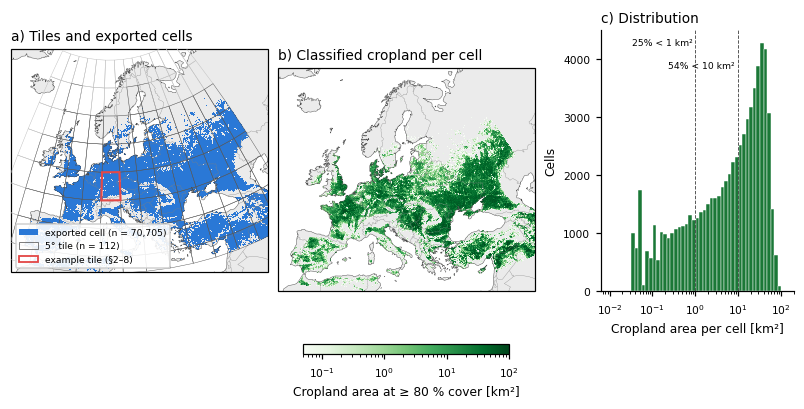

In [5]:
fig = plt.figure(figsize=(7.2, 3.6), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.75])

ax = eu_axes(fig, gs[0], "a) Tiles and exported cells")
eu_map(ax, exported.where(exported), cmap=ListedColormap(["#2a78d6"]))
for w in windows:
    lon0, lat1 = grid_eu.lon_centers[w.c0] - 0.05, grid_eu.lat_centers[w.r0] + 0.05
    lon1, lat0 = grid_eu.lon_centers[w.c1 - 1] + 0.05, grid_eu.lat_centers[w.r1 - 1] - 0.05
    hit = f"{w.r0}_{w.c0}" in tiles_written
    is_example = w == window
    ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, transform=ccrs.PlateCarree(),
                           fill=False, lw=1.4 if is_example else 0.3,
                           ec="#e34948" if is_example else ("0.35" if hit else "0.75"),
                           zorder=5 if is_example else 3))
ax.legend(handles=[Patch(fc="#2a78d6", label=f"exported cell (n = {int(exported.sum()):,})"),
                   Patch(fc="none", ec="0.35", lw=0.5, label=f"5° tile (n = {len(windows)})"),
                   Patch(fc="none", ec="#e34948", lw=1.2, label="example tile (§2–8)")],
          loc="lower left", frameon=True, framealpha=0.9, fontsize=6)

area = unc_eu["total_area_km2"].where(exported)
ax = eu_axes(fig, gs[1], "b) Classified cropland per cell")
im = eu_map(ax, area, cmap="Greens", norm=LogNorm(0.05, 100))
fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.03,
             label="Cropland area at ≥ 80 % cover [km²]")

ax = fig.add_subplot(gs[2])
values = area.values[np.isfinite(area.values)]
ax.hist(values, bins=np.logspace(-2, 2.1, 50), color="#1b7837", edgecolor="white", lw=0.3)
ax.set_xscale("log")
ax.set_xlabel("Cropland area per cell [km²]")
ax.set_ylabel("Cells")
ax.set_title("c) Distribution")
for thr, y in ((1, 0.97), (10, 0.88)):
    share = (values < thr).mean()
    ax.axvline(thr, color="0.3", lw=0.6, ls="--")
    ax.text(thr, ax.get_ylim()[1] * y, f"{share:.0%} < {thr} km² ", fontsize=6, va="top", ha="right")
save(fig, "fig01_domain_tiles_cells")

**Reading.** With `min_cropland_pixels: 1` a cell is exported as soon as one
100 m PROBA-V pixel reaches 80 % cover, so the cell set is wide and its fringe
is thin: panel c gives the share of exported cells whose profile rests on less
than 1 km² (≈ 16 SoilGrids pixels) of cropland.

## 2. SoilGrids 250 m inputs

Ten SoilGrids v2 properties at six depths (60 coverages per tile) are fetched
from the ISRIC WCS for the tile's bounding box plus a one-cell halo, requested
directly in EPSG:4326 (the service reprojects from Homolosine server-side).
Each coverage is then

1. **un-scaled** with the official SoilGrids conversion factors, and
2. **no-data masked**: the WCS GeoTIFFs carry no nodata tag and write `0` over
   water, ice and gaps. For every property where zero is physically
   impossible the zero is masked, so such pixels can neither vote on the soil
   class (a 0/0/0 texture classifies as *sand*) nor enter an aggregate (a pH
   of 0 dominates the H⁺ mean).

This is `SoilGridsHandler._load_fine`, called here unchanged.

In [6]:
handler = SoilGridsHandler(cfg)
fine_raw, reference = handler._load_fine()
fine = {layer: {d: _standardise_lonlat_names(da).load() for d, da in by_depth.items()}
        for layer, by_depth in fine_raw.items()}
DEPTHS = list(soil_cfg.depths)
TOP = DEPTHS[0]
print(f"250 m grid: {reference.shape[0]} x {reference.shape[1]} pixels, "
      f"{len(fine)} properties x {len(DEPTHS)} depths")

250 m grid: 2176 x 2300 pixels, 10 properties x 6 depths


In [7]:
LAYER_INFO = {
    "clay": ("Clay", "%", "arithmetic"), "silt": ("Silt", "%", "arithmetic"),
    "sand": ("Sand", "%", "arithmetic"), "bdod": ("Bulk density", "kg dm⁻³", "arithmetic"),
    "soc": ("Organic carbon", "g kg⁻¹", "geometric"), "phh2o": ("pH (H₂O)", "–", "H⁺ mean"),
    "nitrogen": ("Total nitrogen", "g kg⁻¹", "geometric"),
    "wv0010": ("θ at 10 kPa (saturation)", "vol %", "arithmetic"),
    "wv0033": ("θ at 33 kPa (field capacity)", "vol %", "arithmetic"),
    "wv1500": ("θ at 1500 kPa (wilting point)", "vol %", "arithmetic"),
}
raw_top = {layer: handler._open_coverage(layer, TOP).load() for layer in soil_cfg.layers}
pd.DataFrame([
    {"layer": layer, "property": LAYER_INFO[layer][0], "unit": LAYER_INFO[layer][1],
     "scale factor": SCALE_FACTORS[layer], "aggregation": LAYER_INFO[layer][2],
     "zero-sentinel pixels (0–5 cm) [%]": round(100 * float((raw == 0).mean()), 1)}
    for layer, raw in raw_top.items()
]).set_index("layer")

,property,unit,scale factor,aggregation,zero-sentinel pixels (0–5 cm) [%]
layer,,,,,
clay,Clay,%,10.0,arithmetic,7.4
silt,Silt,%,10.0,arithmetic,7.4
sand,Sand,%,10.0,arithmetic,7.4
bdod,Bulk density,kg dm⁻³,100.0,arithmetic,7.4
soc,Organic carbon,g kg⁻¹,10.0,geometric,7.4
phh2o,pH (H₂O),–,10.0,H⁺ mean,7.4
nitrogen,Total nitrogen,g kg⁻¹,100.0,geometric,7.4
wv0010,θ at 10 kPa (saturation),vol %,10.0,arithmetic,7.4
wv0033,θ at 33 kPa (field capacity),vol %,10.0,arithmetic,7.4


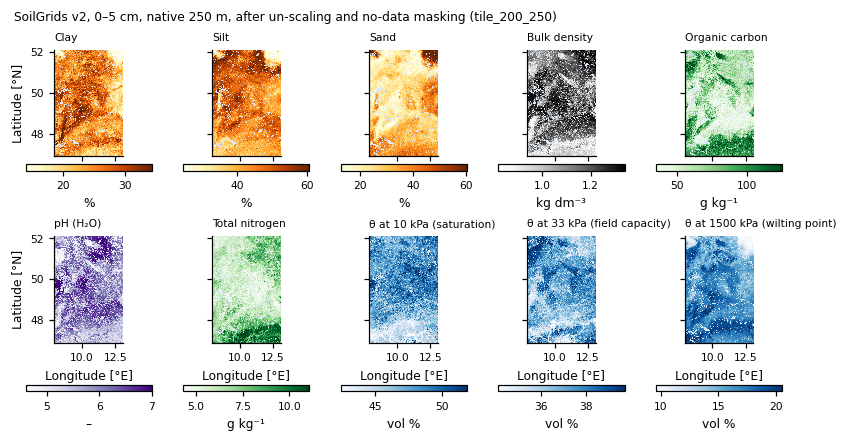

In [8]:
CMAPS = {"clay": "YlOrBr", "silt": "YlOrBr", "sand": "YlOrBr", "bdod": "Greys",
         "soc": "Greens", "nitrogen": "Greens", "phh2o": "Purples",
         "wv0010": "Blues", "wv0033": "Blues", "wv1500": "Blues"}

fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.9), layout="constrained", sharex=True, sharey=True)
for ax, layer in zip(axes.flat, soil_cfg.layers):
    da = fine[layer][TOP]
    lo, hi = np.nanpercentile(da.values, [2, 98])
    im = show(ax, da, cmap=CMAPS[layer], vmin=lo, vmax=hi)
    ax.set_facecolor("#dce9f5")
    ax.set_title(LAYER_INFO[layer][0], fontsize=7)
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.85, pad=0.02,
                 label=LAYER_INFO[layer][1])
for ax in axes.flat:
    ax.label_outer()
fig.suptitle(f"SoilGrids v2, 0–5 cm, native 250 m, after un-scaling and no-data masking "
             f"({window.name})", fontsize=8, x=0.01, ha="left")
save(fig, "fig02_soilgrids_topsoil_250m")

Depth structure of the same inputs on the tile's cropland pixels (defined in
§3): median and interquartile range per SoilGrids horizon. These six horizons
are the source layering every later depth remap starts from.

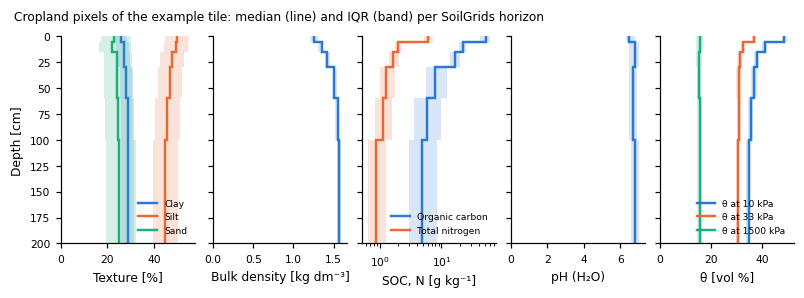

In [9]:
cw = CroplandWeights(cfg)
keep_crop = _standardise_lonlat_names(cw.keep_mask(reference)).load()
crop = keep_crop.values

fig, axes = plt.subplots(1, 5, figsize=(7.2, 2.6), layout="constrained", sharey=True)
GROUPS = [("Texture [%]", ["clay", "silt", "sand"]), ("Bulk density [kg dm⁻³]", ["bdod"]),
          ("SOC, N [g kg⁻¹]", ["soc", "nitrogen"]), ("pH (H₂O)", ["phh2o"]),
          ("θ [vol %]", ["wv0010", "wv0033", "wv1500"])]
for ax, (label, layers) in zip(axes, GROUPS):
    for i, layer in enumerate(layers):
        q = np.array([np.nanpercentile(fine[layer][d].values[crop], [25, 50, 75]) for d in DEPTHS])
        bounds = np.array([depth_bounds_cm(d) for d in DEPTHS])
        edges = np.r_[bounds[:, 0], bounds[-1, 1]]
        ax.stairs(q[:, 1], edges, orientation="horizontal", color=SERIES[i], lw=1.6, baseline=None,
                  label=LAYER_INFO[layer][0].split(" (")[0] if len(layers) > 1 else None)
        ax.fill_betweenx(np.repeat(edges, 2)[1:-1], np.repeat(q[:, 0], 2), np.repeat(q[:, 2], 2),
                         color=SERIES[i], alpha=0.18, lw=0)
    ax.set_xlabel(label)
    if len(layers) > 1:
        ax.legend(frameon=False, fontsize=6, loc="lower right" if layers[0] != "soc" else "lower right")
    if layers == ["soc", "nitrogen"]:
        ax.set_xscale("log")
axes[0].set_ylim(200, 0)
axes[0].set_ylabel("Depth [cm]")
fig.suptitle("Cropland pixels of the example tile: median (line) and IQR (band) per SoilGrids horizon",
             fontsize=8, x=0.01, ha="left")
save(fig, "fig03_soilgrids_depth_profiles")

## 3. Cropland filter

The Copernicus PROBA-V LC100 (2019) `Crops-CoverFraction` layer at 100 m is
the pipeline's only cropland definition. It is resampled onto the SoilGrids
250 m pixel grid (`CroplandWeights.align_to`) and thresholded at
`cropland_min_fraction = 0.8`: a 250 m pixel either enters the classification
and aggregation or it does not — there is no partial weighting downstream.

The same raster and threshold decide which 10 km cells are exported at all
(`CroplandWeights.cell_mask`): a cell needs `min_cropland_pixels` qualifying
**100 m** pixels. Counting on the native grid keeps the cell filter
independent of the soil stage, so weather, soil, site and management share
one cell set.

In [10]:
frac100 = cw.load_fraction().load()
frac250 = _standardise_lonlat_names(cw.align_to(reference)).load()
cell_mask = cw.cell_mask(grid)
crop_pixels_cell = bin_reduce(keep_crop.astype("float32"), grid, lambda x: float(x.sum()), fill=0.0)

ranked, uncertainty = class_composition(
    usda_profile_class(
        usda_texture_class(fine["sand"][TOP], fine["silt"][TOP], fine["clay"][TOP]),
        usda_texture_class(*(rootzone_mean(fine[t], depth_bounds_cm(TOP)[1], soil_cfg.rootzone_bottom_cm)
                             for t in ("sand", "silt", "clay"))),
    ).where(keep_crop, 0).astype("int16"),
    grid, soil_cfg.n_primary_classes, pixel_area=pixel_area_km2(keep_crop),
)

# Zoom: the densely cropped, interior 3 x 3 block whose nine cells carry the
# most distinct dominant classes (ties: the less dominated centre cell).
dom_codes = ranked["class_code"].sel(rank=1).values
dens = crop_pixels_cell.values
ratio = uncertainty["dominance_ratio"].values
n_r, n_c = dom_codes.shape
candidates = [
    ((np.unique(dom_codes[i - 1:i + 2, j - 1:j + 2]).size, ratio[i, j]), i, j)
    for i in range(2, n_r - 2) for j in range(2, n_c - 2)
    if (dens[i - 1:i + 2, j - 1:j + 2] >= 0.3 * dens.max()).all()
]
_, ci, cj = max(candidates)
C_LAT, C_LON = float(grid.lat_centers[ci]), float(grid.lon_centers[cj])
Z = (C_LON - 0.15, C_LON + 0.15, C_LAT - 0.15, C_LAT + 0.15)
print(f"zoom centre cell: {C_LAT:.2f} N, {C_LON:.2f} E, "
      f"{np.unique(dom_codes[ci - 1:ci + 2, cj - 1:cj + 2]).size} dominant classes in the block")

zoom centre cell: 51.15 N, 10.65 E, 5 dominant classes in the block


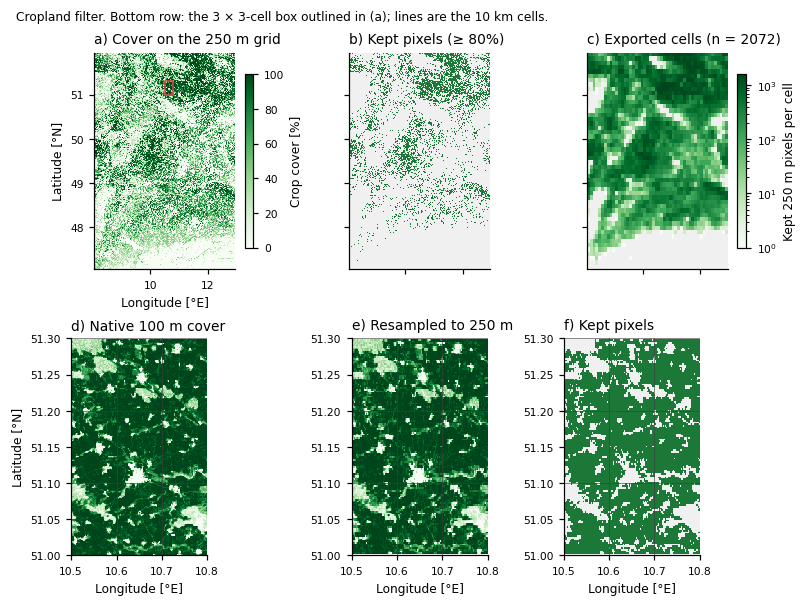

In [11]:
fig = plt.figure(figsize=(7.2, 5.4), layout="constrained")
gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0])
im = show(ax, frac250 * 100, cmap="Greens", vmin=0, vmax=100)
fig.colorbar(im, ax=ax, shrink=0.8, label="Crop cover [%]")
ax.add_patch(Rectangle((Z[0], Z[2]), 0.3, 0.3, fill=False, ec="#e34948", lw=1))
ax.set_title("a) Cover on the 250 m grid")

ax = fig.add_subplot(gs[0, 1], sharex=fig.axes[0], sharey=fig.axes[0])
show(ax, keep_crop.where(keep_crop), cmap=ListedColormap(["#1b7837"]))
ax.set_facecolor(NONCROP)
ax.set_title(f"b) Kept pixels (≥ {soil_cfg.cropland_min_fraction:.0%})")
ax.label_outer()

ax = fig.add_subplot(gs[0, 2], sharex=fig.axes[0], sharey=fig.axes[0])
im = show(ax, crop_pixels_cell.where(cell_mask), cmap="Greens", norm=LogNorm(1, 1600))
ax.set_facecolor(NONCROP)
fig.colorbar(im, ax=ax, shrink=0.8, label="Kept 250 m pixels per cell")
ax.set_title(f"c) Exported cells (n = {int(cell_mask.sum())})")
ax.label_outer()

for k, (title, da, kw) in enumerate([
    ("d) Native 100 m cover", clip_bbox(_standardise_lonlat_names(frac100) * 100, *Z), {"cmap": "Greens", "vmin": 0, "vmax": 100}),
    ("e) Resampled to 250 m", clip_bbox(frac250 * 100, *Z), {"cmap": "Greens", "vmin": 0, "vmax": 100}),
    ("f) Kept pixels", clip_bbox(keep_crop.astype(float), *Z), {"cmap": ListedColormap([NONCROP, "#1b7837"]), "vmin": 0, "vmax": 1}),
]):
    ax = fig.add_subplot(gs[1, k])
    show(ax, da, **kw)
    cell_lines(ax, *Z)
    ax.set_xlim(Z[0], Z[1])
    ax.set_ylim(Z[2], Z[3])
    ax.set_title(title)
    if k:
        ax.set_ylabel("")
fig.suptitle("Cropland filter. Bottom row: the 3 × 3-cell box outlined in (a); lines are the 10 km cells.",
             fontsize=8, x=0.01, ha="left")
save(fig, "fig04_cropland_filter")

Sensitivity of the filter to its threshold, on the example tile: the share of
250 m land pixels retained, and the number of 10 km cells that would be
exported (100 m pixels, `min_cropland_pixels = 1`).

threshold,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
pixels_kept_pct,71.2,67.9,64.8,60.4,55.9,51.5,46.9,43.9,39.6,36.7,33.3,29.9,26.0,22.9,20.4,17.3,14.2,10.4,7.0,4.1
cells_exported,2496.0,2495.0,2495.0,2492.0,2491.0,2474.0,2429.0,2404.0,2370.0,2352.0,2317.0,2270.0,2203.0,2145.0,2115.0,2072.0,2038.0,1969.0,1903.0,1858.0


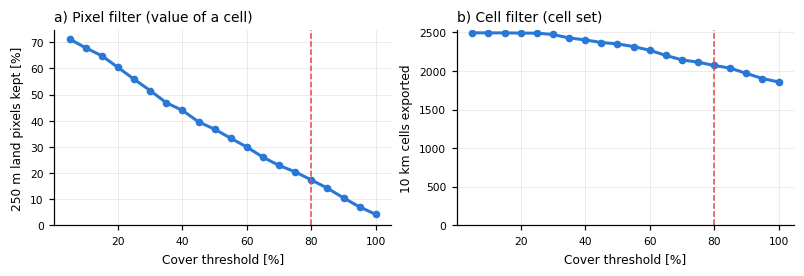

In [12]:
thresholds = np.round(np.arange(0.05, 1.0001, 0.05), 2)
land = np.isfinite(fine["clay"][TOP].values)
f250 = frac250.values
cell_idx, cover = cell_assignment(_standardise_lonlat_names(frac100), grid)
max_cover = pd.Series(cover).groupby(cell_idx).max()
sens = pd.DataFrame({
    "threshold": thresholds,
    "pixels_kept_pct": [100 * np.mean((f250 >= t)[land]) for t in thresholds],
    "cells_exported": [int((max_cover >= t).sum()) for t in thresholds],
})

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), layout="constrained")
for ax, col, label in zip(axes, ["pixels_kept_pct", "cells_exported"],
                          ["250 m land pixels kept [%]", "10 km cells exported"]):
    ax.plot(sens.threshold * 100, sens[col], color="#2a78d6", lw=2, marker="o", ms=4)
    ax.axvline(soil_cfg.cropland_min_fraction * 100, color="#e34948", lw=1, ls="--")
    ax.set_xlabel("Cover threshold [%]")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3, lw=0.5)
    ax.set_ylim(bottom=0)
axes[0].set_title("a) Pixel filter (value of a cell)")
axes[1].set_title("b) Cell filter (cell set)")
save(fig, "fig05_cropland_threshold_sensitivity")
sens.set_index("threshold").T.round(1)

**Reading.** The pixel filter is threshold-sensitive (panel a), the cell filter
almost not (panel b): with one qualifying pixel enough, nearly every cell that
holds any arable land is exported at any threshold. The threshold therefore
mainly decides **which soils describe a cell**, not **which cells exist**.

## 4. Composite texture classification: topsoil × rooting zone

`dominant_mode: usda_profile`. Each cropland pixel receives two USDA texture
classes (12-class triangle):

* **Topsoil key** — the class of the 0–5 cm sand/silt/clay.
* **Rooting-zone key** — the class of the thickness-weighted mean texture
  from 5 cm to `rootzone_bottom_cm = 100 cm`; each horizon contributes its
  overlap with that window.

The pair is packed into one code `(topsoil − 1) · 12 + rootzone` (1–144). A
surface class alone cannot tell uniform sand from sand over loamy till, the
layered profiles common on the North European Plain that decide
plant-available water; the composite key separates them.

In [13]:
top_cls = usda_texture_class(fine["sand"][TOP], fine["silt"][TOP], fine["clay"][TOP])
rz_top = depth_bounds_cm(TOP)[1]
rz_tex = {t: rootzone_mean(fine[t], rz_top, soil_cfg.rootzone_bottom_cm) for t in ("sand", "silt", "clay")}
rz_cls = usda_texture_class(rz_tex["sand"], rz_tex["silt"], rz_tex["clay"])
profile_cls = usda_profile_class(top_cls, rz_cls)
class_fine = profile_cls.where(keep_crop, 0).astype("int16")

weights = {d: max(0.0, min(depth_bounds_cm(d)[1], soil_cfg.rootzone_bottom_cm) - max(depth_bounds_cm(d)[0], rz_top))
           for d in DEPTHS}
pd.Series(weights, name="rooting-zone weight [cm]").to_frame().T

,0-5cm,5-15cm,15-30cm,30-60cm,60-100cm,100-200cm
rooting-zone weight [cm],0.0,10.0,15.0,30.0,40.0,0.0


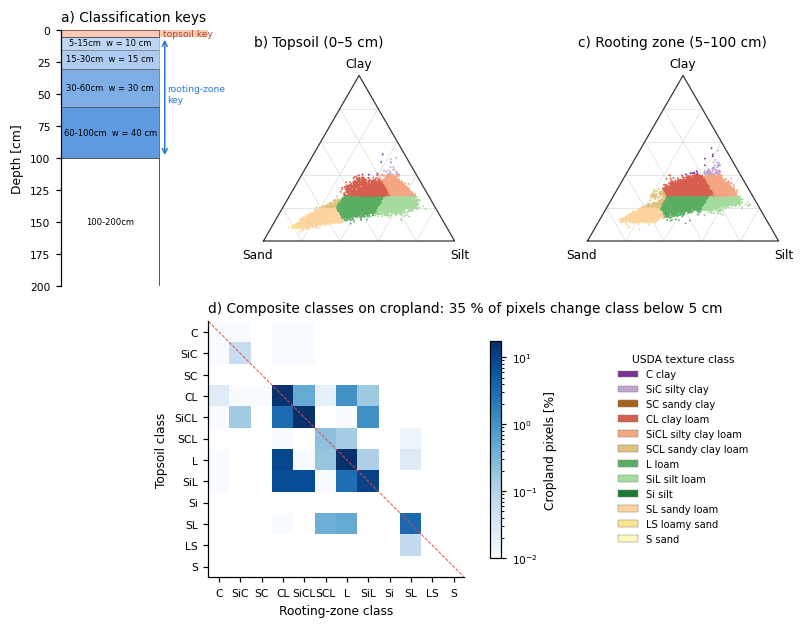

In [14]:
def ternary_xy(sand, silt, clay):
    total = sand + silt + clay
    sand, silt, clay = (100 * v / total for v in (sand, silt, clay))
    return silt + clay / 2, clay * np.sqrt(3) / 2


def ternary_frame(ax):
    h = 100 * np.sqrt(3) / 2
    ax.plot([0, 100, 50, 0], [0, 0, h, 0], color="0.2", lw=0.8)
    for g in range(20, 100, 20):
        kw = {"color": "0.85", "lw": 0.4, "zorder": 0}
        ax.plot([g / 2, 100 - g / 2], [g * np.sqrt(3) / 2] * 2, **kw)
        ax.plot([g, 50 + g / 2], [0, (100 - g) * np.sqrt(3) / 2], **kw)
        ax.plot([g, g / 2], [0, g * np.sqrt(3) / 2], **kw)
    ax.text(-3, -4, "Sand", ha="center", va="top")
    ax.text(103, -4, "Silt", ha="center", va="top")
    ax.text(50, h + 3, "Clay", ha="center", va="bottom")
    ax.set_aspect("equal")
    ax.axis("off")


rng = np.random.default_rng(0)
crop_idx = np.flatnonzero(crop & (class_fine.values > 0))
sample = rng.choice(crop_idx, size=min(40_000, crop_idx.size), replace=False)

fig = plt.figure(figsize=(7.2, 5.6), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[0.7, 1, 1])
ax = fig.add_subplot(gs[0, 0])
bounds = np.array([depth_bounds_cm(d) for d in DEPTHS])
for (lo, hi), d in zip(bounds, DEPTHS):
    w = weights[d]
    ax.add_patch(Rectangle((0, lo), 1.4, hi - lo, fc="#2a78d6" if w else "white",
                           alpha=0.15 + 0.6 * w / max(weights.values()) if w else 1, ec="0.3", lw=0.6))
    if hi - lo >= 10:
        ax.text(0.7, (lo + hi) / 2, f"{d}  w = {w:g} cm" if w else d, ha="center", va="center", fontsize=5.5)
ax.axhspan(0, rz_top, color="#eb6834", alpha=0.35, lw=0)
ax.text(1.45, rz_top / 2, "topsoil key", va="center", fontsize=6, color="#b5481f")
ax.annotate("", xy=(1.48, soil_cfg.rootzone_bottom_cm), xytext=(1.48, rz_top),
            arrowprops={"arrowstyle": "<->", "color": "#2a78d6", "lw": 1})
ax.text(1.52, 50, "rooting-zone\nkey", va="center", fontsize=6, color="#2a78d6")
ax.set_xlim(0, 2.1)
ax.set_ylim(200, 0)
ax.set_xticks([])
ax.set_ylabel("Depth [cm]")
ax.spines["bottom"].set_visible(False)
ax.set_title("a) Classification keys")

for k, (title, cls, tex) in enumerate([
    ("b) Topsoil (0–5 cm)", top_cls, {t: fine[t][TOP] for t in ("sand", "silt", "clay")}),
    (f"c) Rooting zone ({rz_top:g}–{soil_cfg.rootzone_bottom_cm:g} cm)", rz_cls, rz_tex),
]):
    ax = fig.add_subplot(gs[0, k + 1])
    x, y = ternary_xy(*(tex[t].values.ravel()[sample] for t in ("sand", "silt", "clay")))
    c = cls.values.ravel()[sample]
    ax.scatter(x, y, c=[USDA_COLORS.get(v, "white") for v in c], s=1.5, lw=0, rasterized=True)
    ternary_frame(ax)
    ax.set_title(title, pad=14)

ax = fig.add_subplot(gs[1, :2])
codes = USDA_CLASSES.keys()
counts = pd.crosstab(top_cls.values[crop & (class_fine.values > 0)],
                     rz_cls.values[crop & (class_fine.values > 0)]).reindex(index=codes, columns=codes, fill_value=0)
share = 100 * counts / counts.values.sum()
im = ax.imshow(share.where(share > 0), cmap="Blues", norm=LogNorm(0.01, share.values.max()))
ax.plot([-0.5, 11.5], [-0.5, 11.5], color="#e34948", lw=0.6, ls="--")
ax.set_xticks(range(12), [USDA_ABBR[c] for c in codes])
ax.set_yticks(range(12), [USDA_ABBR[c] for c in codes])
ax.set_xlabel("Rooting-zone class")
ax.set_ylabel("Topsoil class")
fig.colorbar(im, ax=ax, shrink=0.85, label="Cropland pixels [%]")
off_diag = 100 - np.trace(share.values)
ax.set_title(f"d) Composite classes on cropland: {off_diag:.0f} % of pixels change class below 5 cm")

ax = fig.add_subplot(gs[1, 2])
usda_legend(ax, loc="center", ncol=1, fontsize=6.5, title="USDA texture class", title_fontsize=7)
ax.axis("off")
save(fig, "fig06_texture_classification")

The two keys mapped at 250 m across the tile's cropland. Panel c marks the
pixels whose rooting-zone class differs from the surface class — the
profiles a topsoil-only (`usda`) classification would pool with uniform ones.

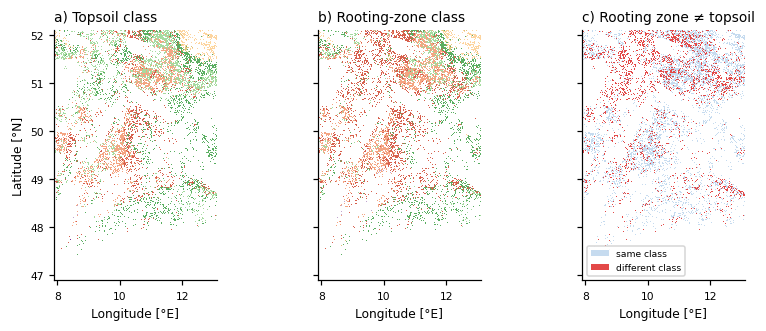

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9), layout="constrained", sharex=True, sharey=True)
show(axes[0], top_cls.where(keep_crop, 0), cmap=USDA_CMAP, norm=USDA_NORM)
axes[0].set_title("a) Topsoil class")
show(axes[1], rz_cls.where(keep_crop, 0), cmap=USDA_CMAP, norm=USDA_NORM)
axes[1].set_title("b) Rooting-zone class")
layered = xr.where(keep_crop & (class_fine > 0), (top_cls != rz_cls).astype(int) + 1, 0)
show(axes[2], layered, cmap=ListedColormap(["#ffffff", "#c6dbef", "#e34948"]), vmin=-0.5, vmax=2.5)
axes[2].set_title("c) Rooting zone ≠ topsoil")
axes[2].legend(handles=[Patch(fc="#c6dbef", label="same class"), Patch(fc="#e34948", label="different class")],
               loc="lower left", fontsize=6)
for ax in axes:
    ax.label_outer()
save(fig, "fig07_texture_class_maps")

## 5. Dominant class per 10 km cell and the pixel mask

Within each 10 km cell the composite classes of the cropland pixels are
ranked by **surface area** (each pixel weighted by its true area,
`R² Δλ (sin φₙ − sin φₛ)`, which matters across 34–72 °N). Rank 1 is the
dominant class; ties go to the lower code. All 250 m pixels that are not of
the dominant class are then dropped, and that **single** pixel mask is
applied to every property at every depth, so a profile is never assembled
from different locations at different depths.

With `aggregation_method: top3` the same is repeated for ranks 2 and 3, each
with its own pixel mask (§10). Rank 1 is identical to single-class
aggregation.

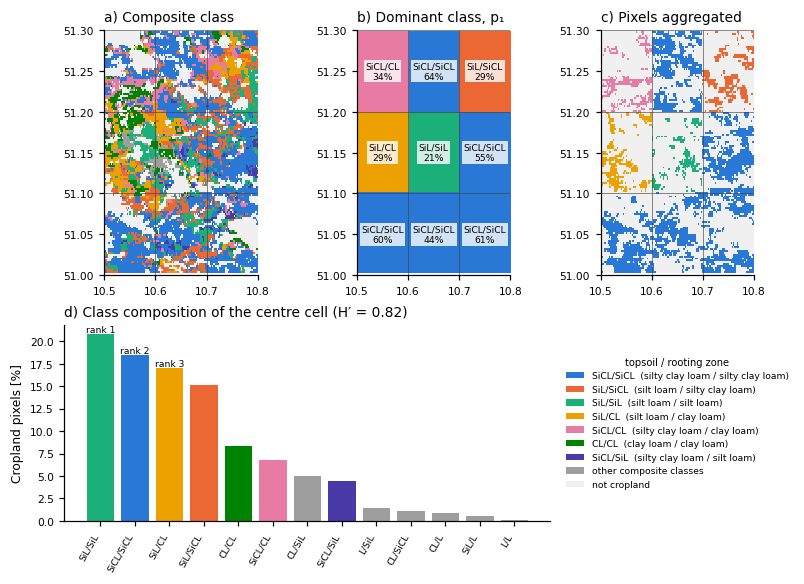

In [16]:
ranked, uncertainty = class_composition(class_fine, grid, soil_cfg.n_primary_classes,
                                        pixel_area=pixel_area_km2(class_fine))
dominant = ranked["class_code"].sel(rank=1, drop=True)
keep_dom = dominant_pixel_mask(class_fine, dominant)

zoom_cls = clip_bbox(class_fine, *Z)
zoom_dom = clip_bbox(keep_dom.astype(float), *Z)
codes_z, counts_z = np.unique(zoom_cls.values[zoom_cls.values > 0], return_counts=True)
order = codes_z[np.argsort(-counts_z)]
colour_of = {int(c): SERIES[i] for i, c in enumerate(order[:len(SERIES)])}


def code_rgb(arr: np.ndarray, faded: np.ndarray | None = None) -> np.ndarray:
    rgb = np.ones(arr.shape + (3,))
    for code in np.unique(arr):
        if code > 0:
            rgb[arr == code] = plt.matplotlib.colors.to_rgb(colour_of.get(int(code), OTHER))
    rgb[arr == 0] = plt.matplotlib.colors.to_rgb(NONCROP)
    if faded is not None:
        rgb[faded] = 0.75 + 0.25 * rgb[faded]
    return rgb


def show_rgb(ax, da, rgb):
    lat, lon = da.lat.values, da.lon.values
    ax.imshow(rgb, extent=[lon.min(), lon.max(), lat.min(), lat.max()],
              origin="upper" if lat[0] > lat[-1] else "lower", interpolation="nearest",
              aspect=1 / np.cos(np.deg2rad(lat.mean())))
    cell_lines(ax, *Z)
    ax.set_xlim(Z[0], Z[1])
    ax.set_ylim(Z[2], Z[3])


fig = plt.figure(figsize=(7.2, 5.2), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.8])
ax = fig.add_subplot(gs[0, 0])
show_rgb(ax, zoom_cls, code_rgb(zoom_cls.values))
ax.set_title("a) Composite class")

ax = fig.add_subplot(gs[0, 1])
dom_z = clip_bbox(dominant, Z[0] - 0.05, Z[1] + 0.05, Z[2] - 0.05, Z[3] + 0.05)
lat_idx = np.abs(dom_z.lat.values[:, None] - zoom_cls.lat.values[None, :]).argmin(0)
lon_idx = np.abs(dom_z.lon.values[:, None] - zoom_cls.lon.values[None, :]).argmin(0)
dom_on_fine = dom_z.values[np.ix_(lat_idx, lon_idx)]
show_rgb(ax, zoom_cls, code_rgb(dom_on_fine))
for la in dom_z.lat.values:
    for lo in dom_z.lon.values:
        if Z[0] < lo < Z[1] and Z[2] < la < Z[3]:
            share1 = float(ranked["area_fraction"].sel(rank=1, lat=la, lon=lo))
            ax.text(lo, la, f"{profile_abbr(int(dom_z.sel(lat=la, lon=lo)))}\n{share1:.0%}",
                    ha="center", va="center", fontsize=6,
                    bbox={"fc": "white", "ec": "none", "alpha": 0.8, "pad": 1})
ax.set_title("b) Dominant class, p₁")
ax.set_ylabel("")

ax = fig.add_subplot(gs[0, 2])
dropped = (zoom_cls.values > 0) & (zoom_dom.values < 0.5)
show_rgb(ax, zoom_cls, code_rgb(np.where(dropped, 0, zoom_cls.values)))
ax.set_title("c) Pixels aggregated")
ax.set_ylabel("")

ax = fig.add_subplot(gs[1, :2])
centre_codes = clip_bbox(class_fine, C_LON - 0.05, C_LON + 0.05, C_LAT - 0.05, C_LAT + 0.05).values
cc, cn = np.unique(centre_codes[centre_codes > 0], return_counts=True)
idx = np.argsort(-cn)
cc, cn = cc[idx], 100 * cn[idx] / cn.sum()
ax.bar(range(cc.size), cn, color=[colour_of.get(int(c), OTHER) for c in cc], width=0.8)
for i in range(min(3, cc.size)):
    ax.text(i, cn[i], f"rank {i + 1}", ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(cc.size), [profile_abbr(int(c)) for c in cc], rotation=60, ha="right", fontsize=6)
ax.set_ylabel("Cropland pixels [%]")
ax.set_title(f"d) Class composition of the centre cell "
             f"(H′ = {float(uncertainty['shannon_entropy'].sel(lat=C_LAT, lon=C_LON)):.2f})")

ax = fig.add_subplot(gs[1, 2])
ax.legend(handles=[Patch(fc=colour_of[int(c)], label=f"{profile_abbr(int(c))}  "
                         f"({USDA_CLASSES[split_profile_class(c)[0]].replace('_', ' ')} / "
                         f"{USDA_CLASSES[split_profile_class(c)[1]].replace('_', ' ')})")
                   for c in order[:len(SERIES)]]
          + [Patch(fc=OTHER, label="other composite classes"), Patch(fc=NONCROP, label="not cropland")],
          loc="center", frameon=False, fontsize=6, title="topsoil / rooting zone", title_fontsize=6.5)
ax.axis("off")
save(fig, "fig08_dominant_class_selection")

### Reproducibility check

Aggregating the dominant pixels with the production reducers and
post-processing must reproduce this tile's
`intermediate_soil_properties_<tile>.nc` exactly.

In [17]:
statistic = soil_cfg.export_statistic
soil_raw, _ = handler._aggregate_masked(fine, keep_dom, statistic)
soil = handler.harmonise_water_retention(handler.normalise_texture(soil_raw))

prod = xr.open_dataset(NC_DIR / f"intermediate_soil_properties_{window.name}.nc")
check = pd.DataFrame({
    v: {"max |rebuild − production|": float(np.nanmax(np.abs(soil[v].values - prod[v].values)[np.isfinite(prod[v].values)])),
        "cells (production)": int(np.isfinite(prod[v].isel(depth=0)).sum())}
    for v in prod.data_vars
}).T
assert (check["max |rebuild − production|"] < 1e-6).all()
check

,max |rebuild − production|,cells (production)
clay,0.0,2040.0
silt,0.0,2040.0
sand,0.0,2040.0
bdod,0.0,2040.0
soc,0.0,2040.0
phh2o,0.0,2040.0
nitrogen,0.0,2040.0
wv0010,0.0,2040.0
wv0033,0.0,2040.0
wv1500,0.0,2040.0


## 6. Variable-specific aggregation rules

The dominant-class pixels of a cell are reduced to one value per property and
depth with a rule matched to the variable's distribution (`reducer_for`):

| Variables | Rule |
| --- | --- |
| clay, silt, sand, bdod, wv0010, wv0033, wv1500 | arithmetic mean |
| soc, nitrogen | geometric mean `exp(mean(ln x))` — right-skewed, log-normal |
| phh2o | mean of `[H⁺] = 10^−pH`, back-transformed `−log₁₀` |

Pixels are equally weighted once they pass the cropland filter. The
figure shows what the rules change relative to a plain arithmetic mean of the
same pixels (topsoil).

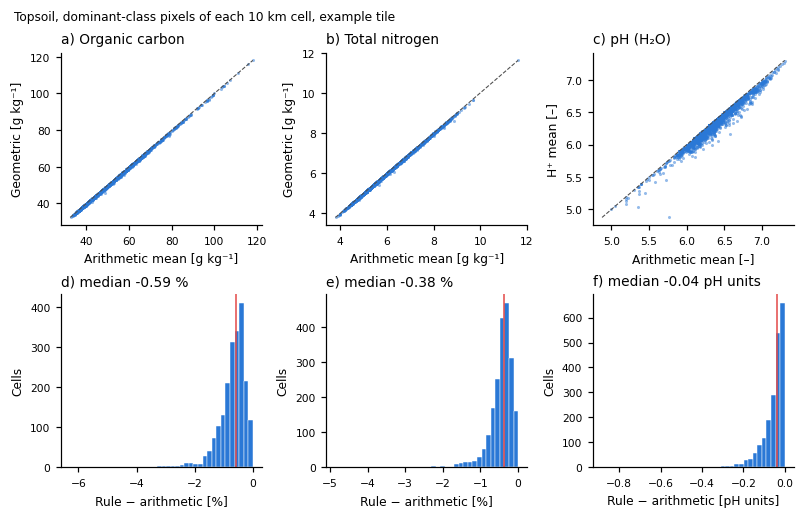

In [18]:
arith = {layer: bin_reduce(fine[layer][TOP].where(keep_dom), grid, cell_mean)
         for layer in ("soc", "nitrogen", "phh2o")}
rule = {layer: soil_raw[layer].sel(depth=TOP) for layer in arith}

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.6), layout="constrained")
for k, layer in enumerate(arith):
    a = arith[layer].values.ravel()
    r = rule[layer].values.ravel()
    ok = np.isfinite(a) & np.isfinite(r)
    a, r = a[ok], r[ok]
    ax = axes[0, k]
    ax.scatter(a, r, s=4, color="#2a78d6", alpha=0.5, lw=0, rasterized=True)
    lims = [min(a.min(), r.min()), max(a.max(), r.max())]
    ax.plot(lims, lims, color="0.3", lw=0.7, ls="--")
    ax.set_xlabel(f"Arithmetic mean [{LAYER_INFO[layer][1]}]")
    ax.set_ylabel(f"{LAYER_INFO[layer][2].capitalize()} [{LAYER_INFO[layer][1]}]")
    ax.set_title(f"{'abc'[k]}) {LAYER_INFO[layer][0]}")
    diff = r - a if layer == "phh2o" else 100 * (r - a) / a
    unit = "pH units" if layer == "phh2o" else "%"
    ax = axes[1, k]
    ax.hist(diff, bins=40, color="#2a78d6", edgecolor="white", lw=0.3)
    ax.axvline(np.median(diff), color="#e34948", lw=1)
    ax.set_xlabel(f"Rule − arithmetic [{unit}]")
    ax.set_ylabel("Cells")
    ax.set_title(f"{'def'[k]}) median {np.median(diff):+.2f} {unit}")
fig.suptitle("Topsoil, dominant-class pixels of each 10 km cell, example tile", fontsize=8, x=0.01, ha="left")
save(fig, "fig09_aggregation_rules")

Both rules sit **below** the arithmetic mean by construction (Jensen's
inequality): the geometric mean damps the high tail of SOC and N, and the H⁺
mean is pulled toward the most acidic pixels because H⁺ activity is linear
where pH is logarithmic.

### Effect of the pixel selection

The same rules applied to three pixel sets per cell: **all** land pixels (a
plain regrid), **cropland** pixels (the 80 % filter), and the **dominant
class** among them (what is exported). The top row shows how far each step
moves the cell value; the bottom row the within-cell standard deviation of
the pixels each set retains — the sub-grid variability the single exported
value stands in for.

,clay: median SD,soc: median SD,paw: median SD
all pixels,2.10,10.25,0.98
cropland,1.95,6.16,0.90
dominant class,1.42,5.79,0.85


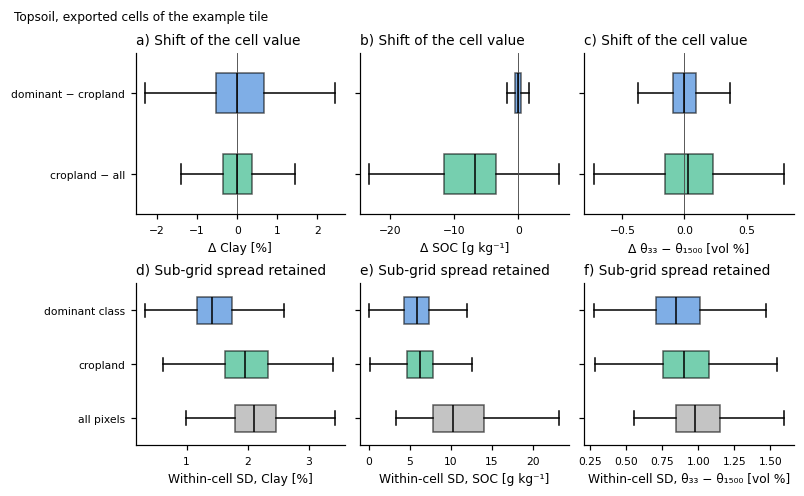

In [19]:
PAW = "paw"


def topsoil_field(layer: str) -> xr.DataArray:
    if layer == PAW:
        return fine["wv0033"][TOP] - fine["wv1500"][TOP]
    return fine[layer][TOP]


VARS = [("clay", "Clay [%]"), ("soc", "SOC [g kg⁻¹]"), (PAW, "θ₃₃ − θ₁₅₀₀ [vol %]")]
SETS = {"all pixels": xr.ones_like(keep_crop, dtype=bool), "cropland": keep_crop, "dominant class": keep_dom}
agg, sd = {}, {}
for layer, _ in VARS:
    reduce = reducer_for("wv0033" if layer == PAW else layer, statistic)
    for name, mask in SETS.items():
        da = topsoil_field(layer).where(mask)
        agg[layer, name] = bin_reduce(da, grid, reduce).where(cell_mask)
        sd[layer, name] = bin_reduce(da, grid, lambda x: float(np.std(x, ddof=1)) if x.size > 1 else np.nan).where(cell_mask)

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.4), layout="constrained")
for k, (layer, label) in enumerate(VARS):
    ax = axes[0, k]
    steps = {"cropland − all": agg[layer, "cropland"] - agg[layer, "all pixels"],
             "dominant − cropland": agg[layer, "dominant class"] - agg[layer, "cropland"]}
    data = [v.values[np.isfinite(v.values)] for v in steps.values()]
    bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops={"color": "black"})
    for patch, colour in zip(bp["boxes"], ["#1baf7a", "#2a78d6"]):
        patch.set_facecolor(colour)
        patch.set_alpha(0.6)
    ax.axvline(0, color="0.3", lw=0.6)
    ax.set_yticks([1, 2], list(steps) if k == 0 else ["", ""])
    ax.set_xlabel(f"Δ {label}")
    ax.set_title(f"{'abc'[k]}) Shift of the cell value")
    ax = axes[1, k]
    data = [sd[layer, s].values[np.isfinite(sd[layer, s].values)] for s in SETS]
    bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops={"color": "black"})
    for patch, colour in zip(bp["boxes"], ["#9e9e9e", "#1baf7a", "#2a78d6"]):
        patch.set_facecolor(colour)
        patch.set_alpha(0.6)
    ax.set_yticks([1, 2, 3], list(SETS) if k == 0 else ["", "", ""])
    ax.set_xlabel(f"Within-cell SD, {label}")
    ax.set_title(f"{'def'[k]}) Sub-grid spread retained")
fig.suptitle("Topsoil, exported cells of the example tile", fontsize=8, x=0.01, ha="left")
save(fig, "fig10_pixel_selection_effect")

pd.DataFrame({
    f"{layer}: median SD": {s: float(np.nanmedian(sd[layer, s].values)) for s in SETS}
    for layer, _ in VARS
}).round(2)

## 7. Post-processing: texture closure and water-retention ordering

Two corrections run per cell **after** aggregation, on every rank:

* **Texture closure.** SoilGrids predicts clay, silt and sand independently,
  and their means need not sum to 100 %. Each is rescaled by
  `100 / (clay + silt + sand)`.
* **Water-retention ordering.** `wv0010`, `wv0033` and `wv1500` also come from
  separate models, so a cell can hold more water at 1500 kPa than at 33 kPa —
  a negative plant-available water. Each drier suction is clipped to the
  wetter one: `θ₁₀ ≥ θ₃₃ ≥ θ₁₅₀₀`.

Panel a is the tile (the closure needs the pre-correction values); panels b
and c are the whole export. The ordering clip is a safeguard: it touches a
small fraction of a percent of cells, almost all below 30 cm.

`wv0033` becomes field capacity (and the initial water content), `wv1500` the
wilting point and `wv0010` saturation. SoilGrids publishes no 0 kPa layer, so
"saturation" here is a drained upper limit at 10 kPa.

,θ₁₅₀₀ = θ₃₃,θ₃₃ = θ₁₀
0-5cm,2,13
5-15cm,1,12
15-30cm,5,34
30-60cm,78,32
60-100cm,88,52
100-200cm,103,98


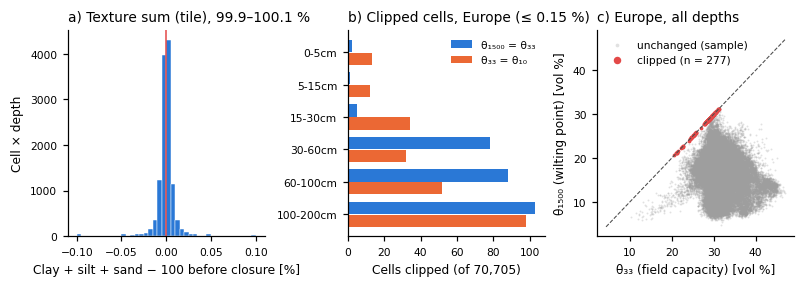

In [20]:
total = (soil_raw["clay"] + soil_raw["silt"] + soil_raw["sand"]).values.ravel()
total = total[np.isfinite(total)]
# The production NetCDFs are stored after clipping, so a clipped cell shows as
# the drier suction exactly equal to the wetter one.
n_exp = int(exported.sum())
viol = pd.DataFrame({
    "θ₁₅₀₀ = θ₃₃": ((props_eu["wv1500"] == props_eu["wv0033"]) & exported).sum(["lat", "lon"]).values,
    "θ₃₃ = θ₁₀": ((props_eu["wv0033"] == props_eu["wv0010"]) & exported).sum(["lat", "lon"]).values,
}, index=DEPTHS)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), layout="constrained")
ax = axes[0]
ax.hist(total - 100, bins=40, color="#2a78d6", edgecolor="white", lw=0.3)
ax.axvline(0, color="#e34948", lw=1)
ax.set_xlabel("Clay + silt + sand − 100 before closure [%]")
ax.set_ylabel("Cell × depth")
ax.set_title(f"a) Texture sum (tile), {total.min():.1f}–{total.max():.1f} %")

ax = axes[1]
y = np.arange(len(DEPTHS))
ax.barh(y - 0.2, viol.iloc[:, 0], height=0.38, color="#2a78d6", label=viol.columns[0])
ax.barh(y + 0.2, viol.iloc[:, 1], height=0.38, color="#eb6834", label=viol.columns[1])
ax.set_yticks(y, DEPTHS)
ax.invert_yaxis()
ax.set_xlabel(f"Cells clipped (of {n_exp:,})")
ax.legend(frameon=False, loc="upper right")
ax.set_title(f"b) Clipped cells, Europe (≤ {100 * viol.values.max() / n_exp:.2f} %)")

ax = axes[2]
fc_ = props_eu["wv0033"].where(exported).values.ravel()
wp_ = props_eu["wv1500"].where(exported).values.ravel()
ok = np.isfinite(fc_) & np.isfinite(wp_)
bad = ok & (wp_ == fc_)
keep_pts = np.flatnonzero(ok & ~bad)
keep_pts = rng.choice(keep_pts, size=min(60_000, keep_pts.size), replace=False)
ax.scatter(fc_[keep_pts], wp_[keep_pts], s=1.5, color="#9e9e9e", alpha=0.3, lw=0, rasterized=True,
           label="unchanged (sample)")
ax.scatter(fc_[bad], wp_[bad], s=6, color="#e34948", lw=0, label=f"clipped (n = {bad.sum()})")
lims = [np.nanmin(wp_), np.nanmax(fc_)]
ax.plot(lims, lims, color="0.3", lw=0.7, ls="--")
ax.set_xlabel("θ₃₃ (field capacity) [vol %]")
ax.set_ylabel("θ₁₅₀₀ (wilting point) [vol %]")
ax.legend(frameon=False, loc="upper left", markerscale=2)
ax.set_title("c) Europe, all depths")
save(fig, "fig11_postprocessing")
viol.round(2)

## 8. Depth remapping and initial mineral N

SoilGrids describes six horizons down to 2 m. The exported files use the
layering of their SIMPLACE reference, read from the reference file itself:

* **wide** `soil.csv` — the Brandenburg reference's six layer bottoms
  (0.1 / 0.3 / 0.5 / 0.7 / 1.0 / 2.0 m);
* **long** `soil_long.csv` — the layering of the EU SUSTAg reference
  (`long_depths: reference`), a two-layer profile of 0.2 m topsoil over
  subsoil to 1.3 m. This is the file the production SIMPLACE solution reads;
  SoilCN indexes its SLIM profile against exactly these two layers.

The remap (`remap_depth_weighted`) is overlap-weighted: each target layer is
the thickness-weighted mean of the source horizons it overlaps.

**Initial mineral N.** SoilGrids `nitrogen` is total N. Bulk density turns it
into a per-layer stock, formed **before** the remap because the stock is
additive over depth:

`stock [kg N ha⁻¹] = N [g kg⁻¹] · BD [kg dm⁻³] · 100 · thickness [cm]`

A fraction `mineral_n_fraction = 1 %` is taken as mineral N and split
`ammonium_share = 30 %` NH₄⁺ / 70 % NO₃⁻. Both are initialisation
assumptions, not measurements. The long dialect writes concentrations
(mg kg⁻¹), inverted from the stock with the same bulk density and thickness.

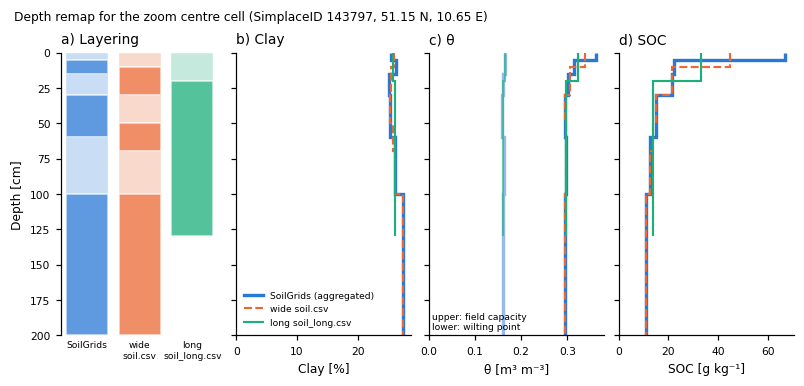

In [21]:
wide = pd.read_csv(RUN / "soil" / "soil.csv")
long = pd.read_csv(RUN / "soil" / "soil_long.csv")
n_lon_eu = grid_eu.shape[1]
row = int(np.abs(grid_eu.lat_centers - C_LAT).argmin())
col = int(np.abs(grid_eu.lon_centers - C_LON).argmin())
loc_id = row * n_lon_eu + col + 1

wide_bottoms = wide.loc[wide.location == loc_id, [f"depth_{i}" for i in range(1, 7)]].values.ravel() * 100
long_rows = long[long.location == loc_id].sort_values("Depth")
long_bottoms = long_rows["Depth"].values * 100
native = np.array([depth_bounds_cm(d) for d in DEPTHS])


def edges(bottoms):
    return np.r_[0, bottoms]


fig = plt.figure(figsize=(7.2, 3.4), layout="constrained")
gs = fig.add_gridspec(1, 4, width_ratios=[0.9, 1, 1, 1])
ax = fig.add_subplot(gs[0])
for x, (label, e) in enumerate([("SoilGrids", np.r_[native[:, 0], native[-1, 1]]),
                                ("wide\nsoil.csv", edges(wide_bottoms)),
                                ("long\nsoil_long.csv", edges(long_bottoms))]):
    for i, (lo, hi) in enumerate(zip(e[:-1], e[1:])):
        ax.add_patch(Rectangle((x + 0.1, lo), 0.8, hi - lo, fc=SERIES[x], alpha=0.25 + 0.5 * (i % 2), ec="white", lw=1))
ax.set_xlim(0, 3)
ax.set_ylim(200, 0)
ax.set_xticks([0.5, 1.5, 2.5], ["SoilGrids", "wide\nsoil.csv", "long\nsoil_long.csv"], fontsize=6)
ax.tick_params(axis="x", length=0)
ax.spines["bottom"].set_visible(False)
ax.set_ylabel("Depth [cm]")
ax.set_title("a) Layering")

cell = soil.sel(lat=C_LAT, lon=C_LON, method="nearest")
PANELS = [("Clay [%]", "clay", "clay_{}", "clay", 1, 1),
          ("θ [m³ m⁻³]", "wv0033", "soilwater_fc_{}", "DUL", 0.01, 1),
          ("SOC [g kg⁻¹]", "soc", "carbon_{}", "OC", 1, 10)]
for k, (label, var, wide_col, long_col, f_native, f_long) in enumerate(PANELS):
    ax = fig.add_subplot(gs[k + 1])
    ax.stairs(cell[var].values * f_native, np.r_[native[:, 0], native[-1, 1]], orientation="horizontal",
              color=SERIES[0], lw=2.2, label="SoilGrids (aggregated)", baseline=None)
    ax.stairs(wide.loc[wide.location == loc_id, [wide_col.format(i) for i in range(1, 7)]].values.ravel(),
              edges(wide_bottoms), orientation="horizontal", color=SERIES[1], lw=1.4, ls="--",
              label="wide soil.csv", baseline=None)
    ax.stairs(long_rows[long_col].values * f_long, edges(long_bottoms), orientation="horizontal",
              color=SERIES[2], lw=1.4, label="long soil_long.csv", baseline=None)
    if var == "wv0033":
        ax.stairs(cell["wv1500"].values * 0.01, np.r_[native[:, 0], native[-1, 1]], orientation="horizontal",
                  color=SERIES[0], lw=2.2, alpha=0.5, baseline=None)
        ax.stairs(long_rows["LL"].values, edges(long_bottoms), orientation="horizontal",
                  color=SERIES[2], lw=1.4, alpha=0.6, baseline=None)
        ax.text(0.02, 0.02, "upper: field capacity\nlower: wilting point", transform=ax.transAxes, fontsize=6)
    ax.set_ylim(200, 0)
    ax.set_xlabel(label)
    ax.set_title(f"{'bcd'[k]}) {label.split(' [')[0]}")
    if k == 0:
        ax.legend(frameon=False, fontsize=6, loc="lower left")
    ax.tick_params(labelleft=False)
fig.suptitle(f"Depth remap for the zoom centre cell (SimplaceID {loc_id}, {C_LAT:.2f} N, {C_LON:.2f} E)",
             fontsize=8, x=0.01, ha="left")
save(fig, "fig12_depth_remap")

## 9. Exported soil properties across Europe

The maps show `soil_long.csv`, the file the production SIMPLACE solution
reads (topsoil = 0–20 cm, subsoil = 20–130 cm). Plant-available water is
`(DUL − LL) · thickness` summed over both layers; initial mineral N is the
NH₄⁺ + NO₃⁻ stock over 0–130 cm, recovered from the concentrations.

,count,mean,std,min,5%,50%,95%,max
"Clay, 0–20 cm",70705.0,26.780,9.173,4.561,9.550,27.634,41.349,58.363
"Sand, 0–20 cm",70705.0,33.671,15.821,1.605,13.828,30.076,67.404,85.774
"Organic C, 0–20 cm",70705.0,3.380,1.766,0.253,1.173,2.943,6.532,24.865
"pH (H₂O), 0–20 cm",70705.0,6.725,0.647,4.598,5.710,6.737,7.765,8.368
"Bulk density, 0–20 cm",70705.0,1.292,0.127,0.809,1.066,1.315,1.474,1.635
"Field capacity, 0–20 cm",70705.0,0.331,0.030,0.092,0.280,0.333,0.373,0.443
"Wilting point, 0–20 cm",70705.0,0.160,0.039,0.059,0.090,0.162,0.222,0.288
"Plant-available water, 0–130 cm",70705.0,187.000,59.132,0.000,88.305,186.898,282.662,392.200
"Initial mineral N, 0–130 cm",70705.0,315.842,139.702,60.618,153.656,288.407,577.031,1903.614


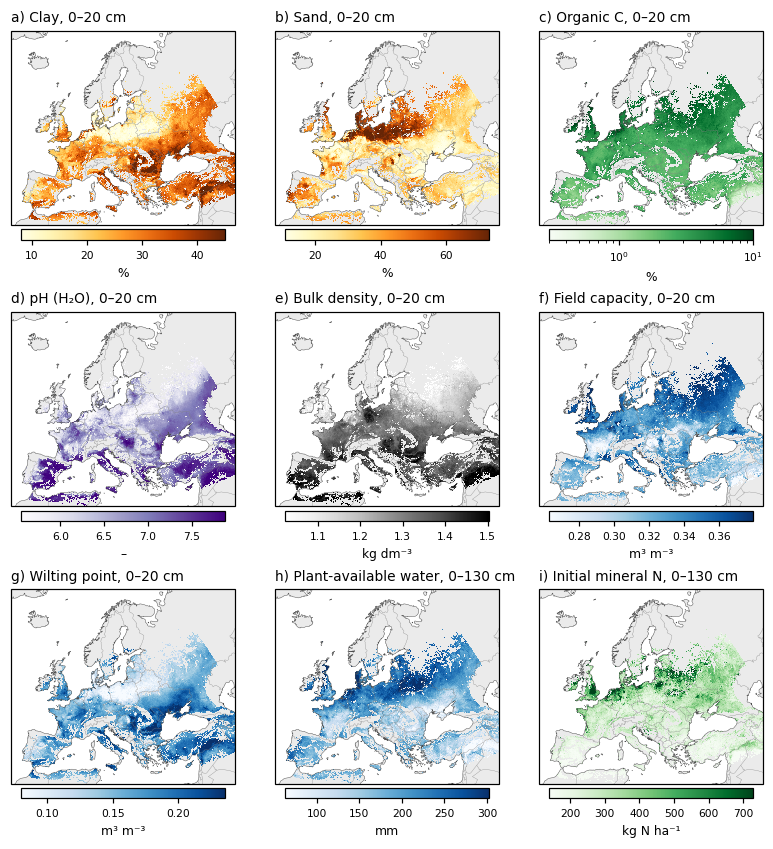

In [22]:
long = long.sort_values(["location", "Depth"])
long["top_cm"] = long.groupby("location")["Depth"].shift(fill_value=0) * 100
long["thick_cm"] = long["Depth"] * 100 - long["top_cm"]
long["paw_mm"] = (long["DUL"] - long["LL"]) * long["thick_cm"] * 10
long["min_n_kg_ha"] = (long["NH4_mg_kg"] + long["NO3_mg_kg"]) * long["thick_cm"] * long["BD"] / 100


def to_grid(ids: np.ndarray, values: np.ndarray) -> xr.DataArray:
    arr = np.full(grid_eu.shape, np.nan)
    ids = np.asarray(ids, dtype=np.int64) - 1
    arr[ids // n_lon_eu, ids % n_lon_eu] = values
    return xr.DataArray(arr, dims=("lat", "lon"),
                        coords={"lat": grid_eu.lat_centers, "lon": grid_eu.lon_centers})


topsoil = long[long.top_cm == 0].set_index("location")
profile = long.groupby("location")[["paw_mm", "min_n_kg_ha"]].sum()
MAPS = [
    ("Clay, 0–20 cm [%]", to_grid(topsoil.index, topsoil["clay"]), "YlOrBr", None),
    ("Sand, 0–20 cm [%]", to_grid(topsoil.index, topsoil["sand"]), "YlOrBr", None),
    ("Organic C, 0–20 cm [%]", to_grid(topsoil.index, topsoil["OC"]), "Greens", LogNorm(0.3, 10)),
    ("pH (H₂O), 0–20 cm", to_grid(topsoil.index, topsoil["ph"]), "Purples", None),
    ("Bulk density, 0–20 cm [kg dm⁻³]", to_grid(topsoil.index, topsoil["BD"]), "Greys", None),
    ("Field capacity, 0–20 cm [m³ m⁻³]", to_grid(topsoil.index, topsoil["DUL"]), "Blues", None),
    ("Wilting point, 0–20 cm [m³ m⁻³]", to_grid(topsoil.index, topsoil["LL"]), "Blues", None),
    ("Plant-available water, 0–130 cm [mm]", to_grid(profile.index, profile["paw_mm"]), "Blues", None),
    ("Initial mineral N, 0–130 cm [kg N ha⁻¹]", to_grid(profile.index, profile["min_n_kg_ha"]), "Greens", None),
]

fig = plt.figure(figsize=(7.2, 7.6), layout="constrained")
gs = fig.add_gridspec(3, 3)
for k, (title, da, cmap, norm) in enumerate(MAPS):
    ax = eu_axes(fig, gs[k // 3, k % 3], f"{'abcdefghi'[k]}) {title.split(' [')[0]}")
    lo, hi = np.nanpercentile(da.values, [2, 98])
    im = eu_map(ax, da, cmap=cmap, norm=norm, **({} if norm else {"vmin": lo, "vmax": hi}))
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.02,
                 label=title.split(" [")[-1].rstrip("]") if "[" in title else "–")
save(fig, "fig13_exported_soil_maps")

pd.DataFrame({title.split(" [")[0]: pd.Series(da.values.ravel()).describe(percentiles=[0.05, 0.5, 0.95])
              for title, da, *_ in MAPS}).T.round(3)

**Caveat for panel i.** Initial mineral N is an assumption, not a
measurement: 1 % of the total-N stock. Over 0–130 cm it comes out several
times above the 30–90 kg N ha⁻¹ typically measured as pre-sowing Nmin on
European arable land (a fraction near 0.2 % would land in that range). The
production run used it as configured; state it as an initialisation
assumption in the text, or recalibrate before relying on N-limited yields.

In [23]:
min_n = profile["min_n_kg_ha"]
print(f"initial mineral N, 0-130 cm: median {min_n.median():.0f} kg N/ha "
      f"(5-95 %: {min_n.quantile(0.05):.0f}-{min_n.quantile(0.95):.0f})")

initial mineral N, 0-130 cm: median 288 kg N/ha (5-95 %: 154-577)


Dominant classes across Europe: the topsoil part of the rank-1 composite
class, where the rooting zone falls in a different class (the layered
profiles the composite key keeps apart), and the cropland area each composite
class represents as rank 1.

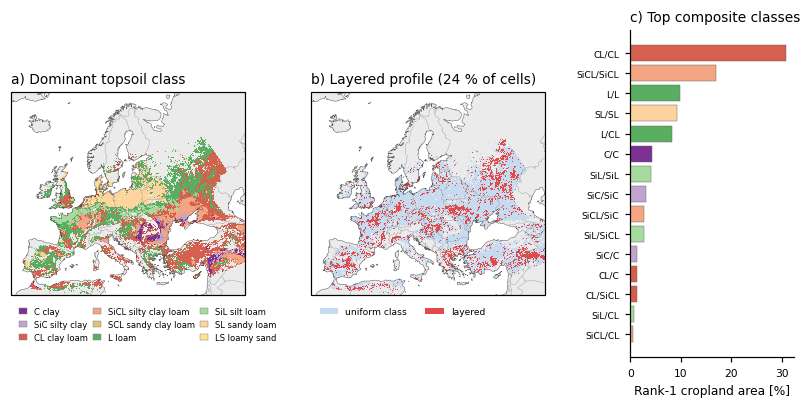

In [24]:
code1 = top_eu["class_code"].sel(rank=1).where(exported)
top_part = xr.apply_ufunc(lambda c: np.where(c > 0, (c - 1) // 12 + 1, 0), code1.fillna(0)).where(exported)
root_part = xr.apply_ufunc(lambda c: np.where(c > 0, (c - 1) % 12 + 1, 0), code1.fillna(0)).where(exported)
layered_eu = (top_part != root_part).where(exported)

area1 = top_eu["area_km2"].sel(rank=1).where(exported)
by_class = (pd.DataFrame({"code": code1.values.ravel(), "area": area1.values.ravel()})
            .dropna().groupby("code")["area"].sum().sort_values(ascending=False))
by_class.index = by_class.index.astype(int)
top15 = by_class.head(15)

fig = plt.figure(figsize=(7.2, 3.6), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.7], wspace=0.12)
ax = eu_axes(fig, gs[0], "a) Dominant topsoil class")
eu_map(ax, top_part, cmap=USDA_CMAP, norm=USDA_NORM)
present = sorted(int(c) for c in np.unique(top_part.values[np.isfinite(top_part.values)]) if c > 0)
usda_legend(ax, present, loc="upper left", bbox_to_anchor=(0, -0.02), ncol=3, fontsize=5.5,
            handlelength=1, columnspacing=0.6)

ax = eu_axes(fig, gs[1], f"b) Layered profile ({100 * float(layered_eu.mean()):.0f} % of cells)")
eu_map(ax, layered_eu, cmap=ListedColormap(["#c6dbef", "#e34948"]), vmin=0, vmax=1)
ax.legend(handles=[Patch(fc="#c6dbef", label="uniform class"), Patch(fc="#e34948", label="layered")],
          loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2, fontsize=6, frameon=False)

ax = fig.add_subplot(gs[2])
share = 100 * top15 / by_class.sum()
ax.barh(range(top15.size), share, color=[USDA_COLORS[split_profile_class(c)[0]] for c in top15.index],
        edgecolor="0.4", lw=0.3)
ax.set_yticks(range(top15.size), [profile_abbr(c) for c in top15.index], fontsize=6)
ax.invert_yaxis()
ax.set_xlabel("Rank-1 cropland area [%]")
ax.set_title("c) Top composite classes")
save(fig, "fig14_dominant_classes_europe")

## 10. Within-cell heterogeneity: the top-3 classes

The exported profile represents only the dominant class's share of a cell's
cropland. Per cell:

* **area fraction** `pᵢ` of rank *i*, from true pixel areas;
* **dominance ratio** `U_d = 1 − p₁` — the share the exported profile does
  not represent;
* **normalised Shannon entropy** `H′ = −Σ pᵢ ln pᵢ / ln N` over all *N*
  classes present (0 = one class, 1 = all equally frequent).

Ranks 2 and 3 are aggregated over their own pixels exactly like rank 1 and
written as `soil_2.csv`, `soil_3.csv`.

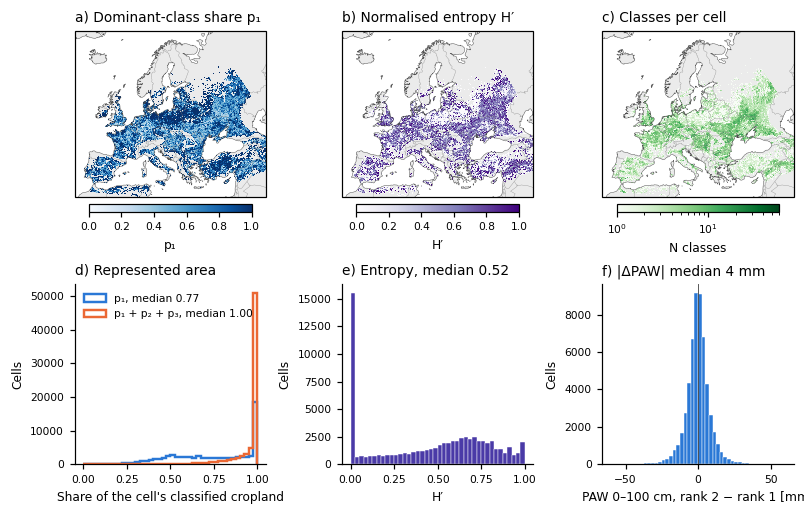

In [25]:
p1 = unc_eu["area_fraction"].sel(rank=1).where(exported)
p123 = unc_eu["area_fraction"].sum("rank").where(exported)
ent_eu = unc_eu["shannon_entropy"].where(exported)
ncls = unc_eu["n_classes"].where(exported)

fig = plt.figure(figsize=(7.2, 5.6), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 0.75])
for k, (title, da, cmap, kw, label) in enumerate([
    ("a) Dominant-class share p₁", p1, "Blues", {"vmin": 0, "vmax": 1}, "p₁"),
    ("b) Normalised entropy H′", ent_eu, "Purples", {"vmin": 0, "vmax": 1}, "H′"),
    ("c) Classes per cell", ncls, "Greens", {"norm": LogNorm(1, 60)}, "N classes"),
]):
    ax = eu_axes(fig, gs[0, k], title)
    im = eu_map(ax, da, cmap=cmap, **kw)
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.85, pad=0.02, label=label)

ax = fig.add_subplot(gs[1, 0])
for i, (lab, da) in enumerate([("p₁", p1), ("p₁ + p₂ + p₃", p123)]):
    v = da.values[np.isfinite(da.values)]
    ax.hist(v, bins=np.linspace(0, 1, 41), histtype="step", lw=1.6, color=SERIES[i],
            label=f"{lab}, median {np.median(v):.2f}")
ax.set_xlabel("Share of the cell's classified cropland")
ax.set_ylabel("Cells")
ax.legend(frameon=False, loc="upper left")
ax.set_title("d) Represented area")

ax = fig.add_subplot(gs[1, 1])
v = ent_eu.values[np.isfinite(ent_eu.values)]
ax.hist(v, bins=40, color="#4a3aa7", edgecolor="white", lw=0.3)
ax.set_xlabel("H′")
ax.set_ylabel("Cells")
ax.set_title(f"e) Entropy, median {np.median(v):.2f}")

ax = fig.add_subplot(gs[1, 2])
paw_native = ((top_eu["wv0033"] - top_eu["wv1500"]) / 100
              * xr.DataArray([max(0.0, min(b, 100) - a) * 10 for a, b in native], dims="depth",
                             coords={"depth": top_eu.depth})).sum("depth", min_count=1)
d_paw = (paw_native.sel(rank=2) - paw_native.sel(rank=1)).where(exported)
d_clay = (top_eu["clay"].sel(rank=2, depth=TOP) - top_eu["clay"].sel(rank=1, depth=TOP)).where(exported)
v = d_paw.values[np.isfinite(d_paw.values)]
ax.hist(np.clip(v, -60, 60), bins=np.linspace(-60, 60, 49), color="#2a78d6", edgecolor="white", lw=0.3)
ax.axvline(0, color="0.3", lw=0.6)
ax.set_xlabel("PAW 0–100 cm, rank 2 − rank 1 [mm]")
ax.set_ylabel("Cells")
ax.set_title(f"f) |ΔPAW| median {np.median(np.abs(v)):.0f} mm")
save(fig, "fig15_heterogeneity_top3")

## 11. Numbers for the methods text

In [26]:
crop_area_total = float(unc_eu["total_area_km2"].where(exported).sum())
rank1_area = float(top_eu["area_km2"].sel(rank=1).where(exported).sum())
rank123_area = float(top_eu["area_km2"].where(exported).sum())
n_cells = int(exported.sum())
summary = pd.Series({
    "Target grid cells": f"{exported.size:,}",
    "Tiles processed / with output": f"{len(windows)} / {len(tiles_written)}",
    "Exported cells": f"{n_cells:,}",
    "Exported cells with < 1 km² cropland": f"{100 * float((unc_eu['total_area_km2'].where(exported) < 1).sum()) / n_cells:.1f} %",
    "Classified cropland area (≥ 80 % cover)": f"{crop_area_total:,.0f} km²",
    "Represented by rank-1 profiles": f"{100 * rank1_area / crop_area_total:.1f} %",
    "Represented by ranks 1–3": f"{100 * rank123_area / crop_area_total:.1f} %",
    "Median p₁ / median H′": f"{float(p1.median()):.2f} / {float(ent_eu.median()):.2f}",
    "Cells with a layered dominant profile": f"{100 * float(layered_eu.mean()):.1f} %",
    "Distinct rank-1 composite classes": f"{by_class.size}",
    "Cells in soil_1 / soil_2 / soil_3": " / ".join(
        f"{int(top_eu['class_code'].sel(rank=r).where(exported).pipe(lambda d: (d > 0).sum())):,}" for r in (1, 2, 3)),
    "Example tile: 250 m pixels / kept as cropland": f"{class_fine.size:,} / {100 * crop.mean():.1f} %",
    "Example tile: cropland pixels with layered class": f"{off_diag:.1f} %",
    "Cells with θ₁₅₀₀ clipped to θ₃₃ (any depth)": f"{100 * float(((props_eu['wv1500'] == props_eu['wv0033']) & exported).any('depth').sum()) / n_cells:.2f} %",
    "Long-layout layer bottoms": ", ".join(f"{b / 100:g} m" for b in long_bottoms),
}, name="value")
summary.to_csv(FIG_DIR / "methods_numbers.csv")
summary.to_frame()

,value
Target grid cells,"262,200"
Tiles processed / with output,112 / 79
Exported cells,"70,705"
Exported cells with < 1 km² cropland,24.7 %
Classified cropland area (≥ 80 % cover),"1,124,116 km²"
Represented by rank-1 profiles,68.2 %
Represented by ranks 1–3,94.4 %
Median p₁ / median H′,0.77 / 0.52
Cells with a layered dominant profile,23.6 %
Distinct rank-1 composite classes,40
